In [ ]:
import json
import xarray as xr
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
import access_ec_on_maap as maap
sys.path.append("/home/jmayer/ACI_research/ectools/")
from ectools import ecio

# find orbits in sc regions (doesnt have to be downloaded)

In [23]:
# load the already known files in the stratus regions
save_path = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/acmcap_orbits_in_sc_regions.json'


allowed_frames = ['A','B','D','E']
year = '2025'
if year == '2024':
    months_to_process = ['08','09','10','11','12']
else:
    months_to_process = ['01','02','03','04','05','06','07','08','09','10','11']

for region in ['SEA','SEP','NEA','NEP']:
    for month in months_to_process:
        print(f'\nProcessing year {year}, month: {month}')
        days_in_month = 31
        if month in ['04','06','09','11']:
            days_in_month = 30
        elif month == '02':
            days_in_month = 28

        ds_url_list = maap.get_ec_data_url_via_maap(datetime_range=[f'{year}-{month}-01T00:00:00Z', f'{year}-{month}-{days_in_month}T23:59:59Z'], 
                                    product='ACM_CAP_2B', 
                                    region=region,
                                    frame=None,
                                    orbitNumber=None,
                                    productVersion = 'ba',
                                    ec_collection=['EarthCAREL2Validated_MAAP'],
                                    max_items=200)

        # construct file paths from URLs
        found_acmcap_list = []
        for url, orbit in ds_url_list:
            # extract filename and date information
            filename = url.split('/')[-1]
            date = filename.split('ACM_CAP_2B_')[1].split('_')[0][0:8]
            orbitNumber = orbit[:-1]
            frame = orbit[-1]
            if frame not in allowed_frames: # overlapping parts of other frames are ignored
                continue

            file_info = {'date': date, 'orbitNumber': orbitNumber, 'frame': frame, 'filename': filename}
            found_acmcap_list.append(file_info)
        found_acmcap_list.sort(key=lambda x: x['orbitNumber'])
        
        # load existing data
        with open(save_path, 'r') as file:
            orbits_in_stratus_regions = json.load(file)
        
        # check each file whether it exists and is already known
        for file_info in found_acmcap_list:

            file_already_known = False
            # check whether file is already in the list of known files
            for _, known_file_paths in orbits_in_stratus_regions.items():
                if file_info in known_file_paths:
                    print('File already known: ', file_info)
                    file_already_known = True
                    break
            # if not known, add file to the list to be saved
            if not file_already_known:
                orbits_in_stratus_regions[region].append(file_info)

        # Save the dictionary to a JSON file after each month
        with open(save_path, 'w') as file:
            json.dump(orbits_in_stratus_regions, file, indent=4)


Processing year 2025, month: 01
Accessing 82 items (limited by max_items).
82 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/01/01/ECA_EXBA_ACM_CAP_2B_20250101T124024Z_20250919T063000Z_03385E/ECA_EXBA_ACM_CAP_2B_20250101T124024Z_20250919T063000Z_03385E/ECA_EXBA_ACM_CAP_2B_20250101T124024Z_20250919T063000Z_03385E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/01/01/ECA_EXBA_ACM_CAP_2B_20250101T124024Z_20250919T063000Z_03385E/ECA_EXBA_ACM_CAP_2B_20250101T124024Z_20250919T063000Z_03385E/ECA_EXBA_ACM_CAP_2B_20250101T124024Z_20250919T063000Z_03385E.h5
Orbit: 03385E
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/01/10/ECA_EXBA_ACM_CAP_2B_20250110T123634Z_20250919T082951Z_03525E/ECA_EXBA_ACM_CAP_2B_20250110T123634Z_20250919T082951Z_03525E/ECA_EXBA_ACM_CAP_2B_20250110T1236

In [24]:
# sort the entries by orbit number
with open(save_path, 'r') as file:
    orbits_in_stratus_regions = json.load(file)

for region in ['SEA','SEP','NEA','NEP']:
    orbits_in_stratus_regions[region].sort(key=lambda x: x['orbitNumber'])

with open(save_path, 'w') as file:
    json.dump(orbits_in_stratus_regions, file, indent=4)

## test orbits in sc regions

In [30]:
save_path = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/acmcap_orbits_in_sc_regions.json'
with open(save_path, 'r') as file:
    orbits_in_stratus_regions = json.load(file)

In [31]:
orbits_in_stratus_regions

{'SEA': [{'date': '20240801',
   'orbitNumber': '01005',
   'frame': 'E',
   'filename': 'ECA_EXBA_ACM_CAP_2B_20240801T132709Z_20250905T073323Z_01005E.h5'},
  {'date': '20240802',
   'orbitNumber': '01013',
   'frame': 'A',
   'filename': 'ECA_EXBA_ACM_CAP_2B_20240802T010156Z_20250905T180146Z_01013A.h5'},
  {'date': '20240802',
   'orbitNumber': '01021',
   'frame': 'E',
   'filename': 'ECA_EXBA_ACM_CAP_2B_20240802T140913Z_20250905T175456Z_01021E.h5'},
  {'date': '20240803',
   'orbitNumber': '01029',
   'frame': 'A',
   'filename': 'ECA_EXBA_ACM_CAP_2B_20240803T014359Z_20250905T123735Z_01029A.h5'},
  {'date': '20240803',
   'orbitNumber': '01036',
   'frame': 'E',
   'filename': 'ECA_EXBA_ACM_CAP_2B_20240803T131837Z_20250905T144107Z_01036E.h5'},
  {'date': '20240804',
   'orbitNumber': '01045',
   'frame': 'A',
   'filename': 'ECA_EXBA_ACM_CAP_2B_20240804T022558Z_20250905T193409Z_01045A.h5'},
  {'date': '20240804',
   'orbitNumber': '01052',
   'frame': 'E',
   'filename': 'ECA_EXBA_A

Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/12/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/12/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A.h5
Orbit: 01169A
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/12/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A/ECA_EXBA_ACM_CAP_2B_20240812T014958Z_20250905T114942Z_01169A/ECA_EXBA_ACM_CAP_2B_2024081

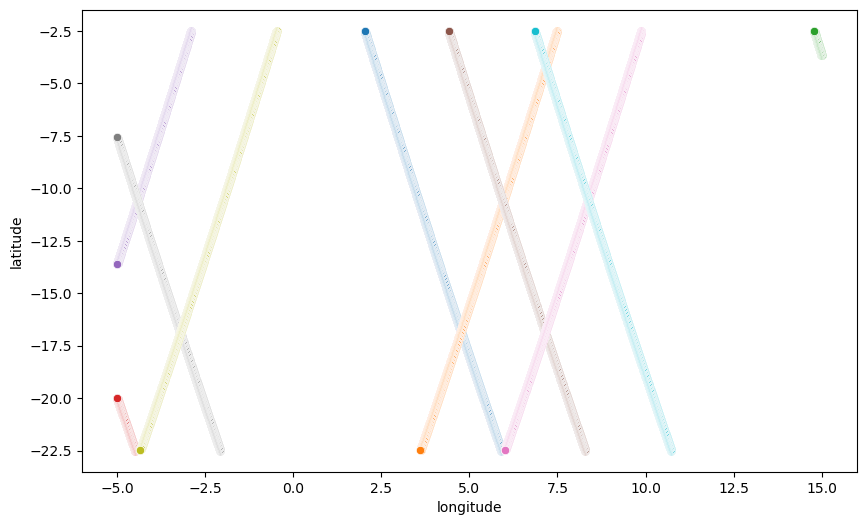

In [32]:
region = 'SEA'
plt.figure(figsize=(10,6))
for item in orbits_in_stratus_regions[region][15:25]:
    frame = item['frame']
    orbitNumber = item['orbitNumber']

    ACMCAP_list = maap.get_acmcap_via_maap(
                        region=region, 
                        frame=frame,
                        orbitNumber=orbitNumber,
                        max_items=1,
                        )
    ACMCAP = ACMCAP_list[0][0]
    sns.scatterplot(x=ACMCAP.longitude, y=ACMCAP.latitude)

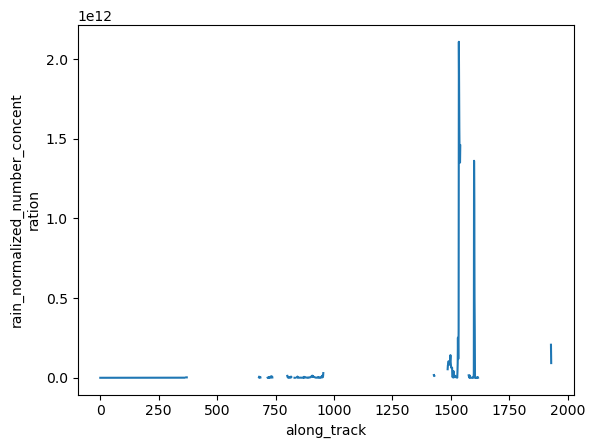

In [37]:
ACMCAP.rain_normalized_number_concentration.mean(dim='JSG_height').plot()

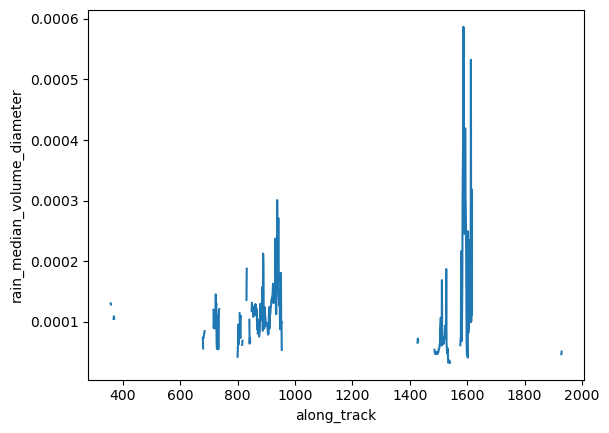

In [46]:
dsp=ACMCAP
dsp.rain_median_volume_diameter.where(dsp.rain_water_content > 0).mean(dim='JSG_height').plot()

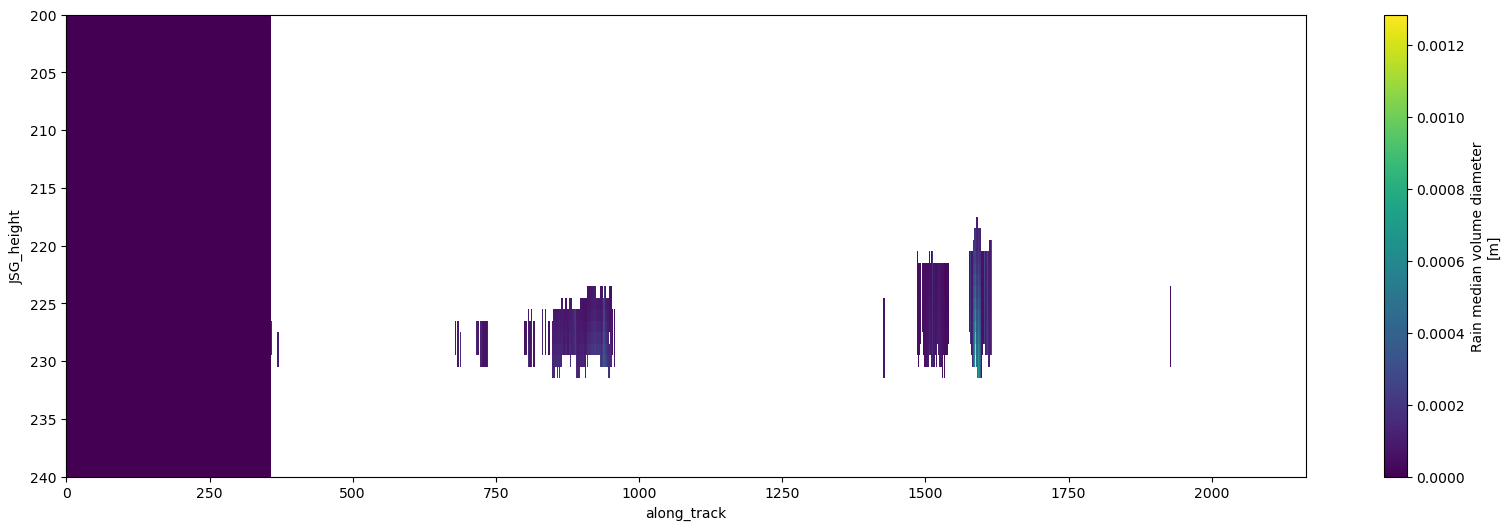

In [41]:
ACMCAP.rain_median_volume_diameter.T.plot(ylim=(240,200), figsize=(20,6))

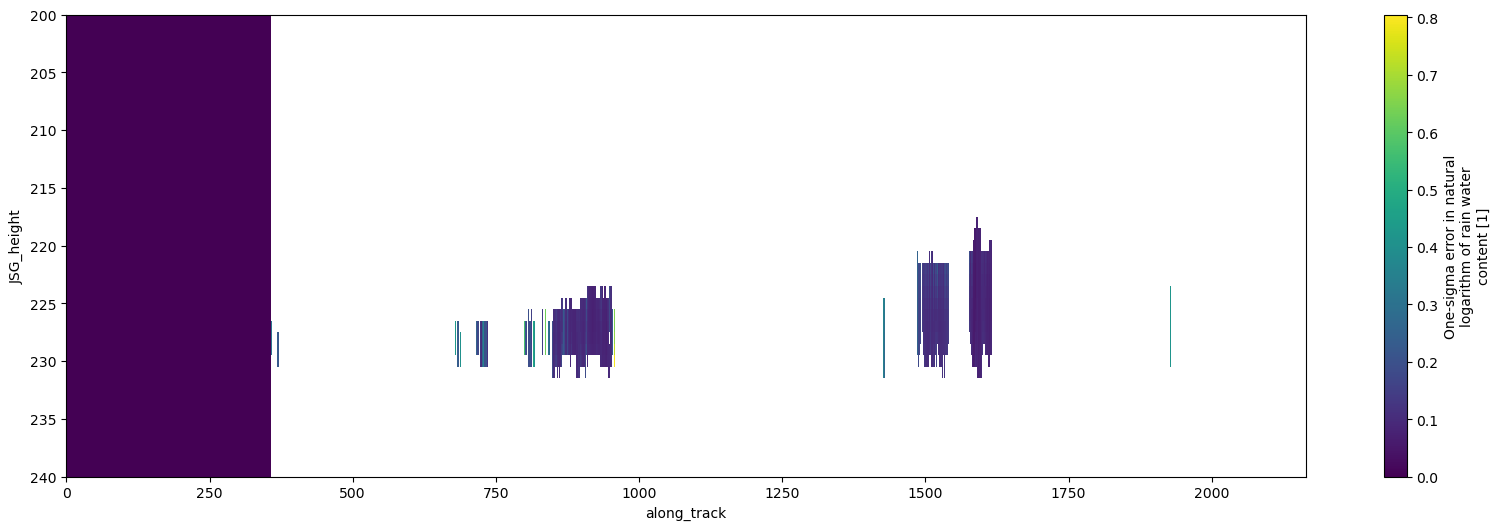

In [47]:
ACMCAP.rain_water_content_error.T.plot(ylim=(240,200), figsize=(20,6))

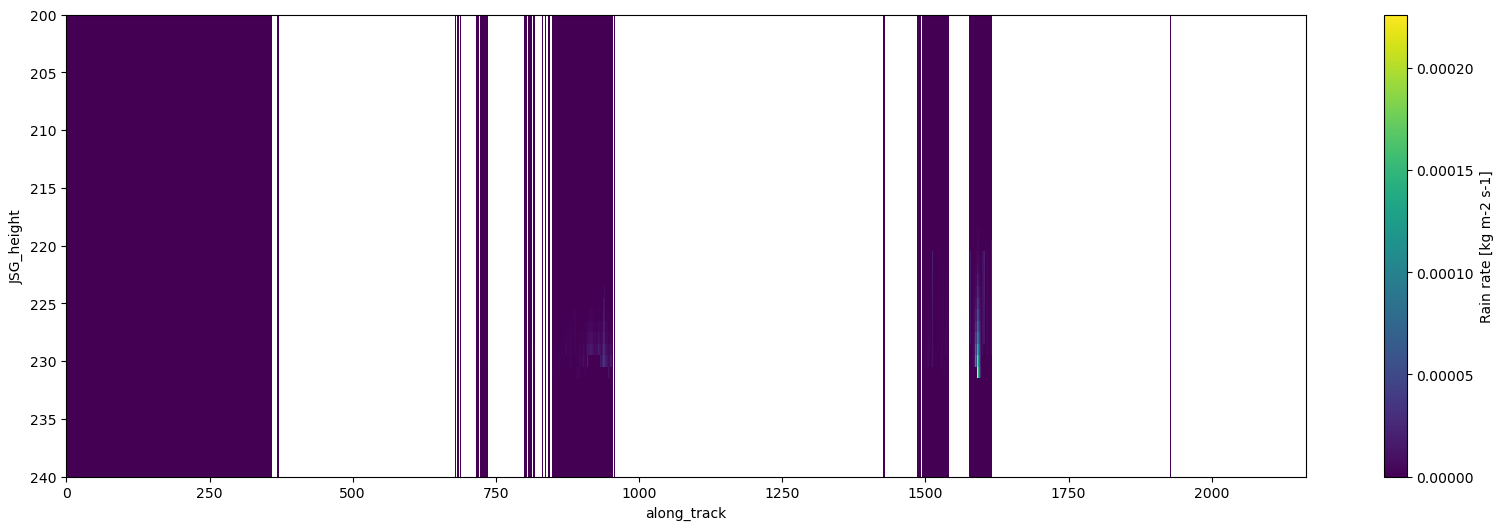

In [43]:
ACMCAP.rain_rate.T.plot(ylim=(240,200), figsize=(20,6))

In [33]:
ACMCAP

<xarray.Dataset> Size: 245MB
Dimensions:                                                         (
                                                                     along_track: 2165,
                                                                     JSG_height: 242,
                                                                     MSI_longwave_channel: 3,
                                                                     MSI_shortwave_channel: 1)
Dimensions without coordinates: along_track, JSG_height, MSI_longwave_channel,
                                MSI_shortwave_channel
Data variables: (12/192)
    time                                                            (along_track) datetime64[ns] 17kB ...
    latitude                                                        (along_track) float64 17kB ...
    longitude                                                       (along_track) float64 17kB ...
    height                                                          (along_track, JSG_height) float32 2MB ...
    geoid_offset                                                    (along_track) float32 9kB ...
    elevation                                                       (along_track) float32 9kB ...
    ...                                                              ...
    MSI_shortwave_observation_variable_count                        (along_track) int32 9kB ...
    MSI_shortwave_cost_function                                     (along_track) float32 9kB ...
    MSI_shortwave_wavelength                                        (MSI_shortwave_channel) float32 4B ...
    MSI_shortwave_albedo_forward                                    (along_track, MSI_shortwave_channel) float32 9kB ...
    MSI_shortwave_albedo                                            (along_track, MSI_shortwave_channel) float32 9kB ...
    MSI_shortwave_albedo_assimilation_status                        (along_track) int8 2kB ...